# 2 · Explore: what can a satellite see, and what lies beneath?

**Syllabus:** Module 2 (import, filter, group, rank, plots) and Module 3 (descriptive
statistics, correlation, estimation, hypothesis testing).

Satellites measure the ocean's **surface** every day: temperature, salinity, sea
level, currents and winds. Cyclone forecasters need the heat **below** the surface,
which satellites cannot see. Argo floats measure it, but only at a few hundred places a
month.

The prediction task of this project: **from what a satellite sees today, estimate the
temperature at 15 depths, from 0 to 1,000 m**.

The dataset: 217,120 rows. Each row is one 0.25° patch of the North Indian Ocean on one
day between 2010 and 2024, sampled at random (40 patches a day). It holds the 8
satellite measurements of that patch and the temperature at 15 depths from GLORYS, the
European ocean reanalysis (the best available estimate of the true 3D ocean).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import common as C

C.style()
df = C.load_cells()
df = df[df["split"] != "gap"]           # the month-long gaps between the train, validation and test years
SEASONS = {1: "Winter", 2: "Winter", 3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
           6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
           10: "Post-monsoon", 11: "Post-monsoon", 12: "Post-monsoon"}     # India Meteorological Department
df["season"] = df["day"].dt.month.map(SEASONS)
print(df.shape)
df.head()

(214640, 33)


,day,split,lat,lon,bathy,sst,sss,adt,sla,uc,...,t200,t300,t500,t700,t1000,doy,doy_sin,doy_cos,basin,season
0,2010-02-04,train,13.875,61.125,4185.2998,26.3572,36.3272,0.7441,0.0453,-0.0355,...,16.8582,14.0813,12.2305,11.4667,8.7689,35,0.566362,0.824157,Arabian Sea,Winter
1,2010-02-04,train,14.625,91.625,2700.6167,27.1816,32.0480,0.9813,0.0344,-0.1742,...,14.1912,11.5201,9.7244,8.3186,6.4129,35,0.566362,0.824157,Bay of Bengal,Winter
2,2010-02-04,train,9.875,68.875,4536.3447,28.5644,35.9602,0.7995,0.0650,0.1589,...,15.5314,12.8151,11.0990,10.0226,7.7164,35,0.566362,0.824157,Arabian Sea,Winter
3,2010-02-04,train,7.625,50.875,3336.9084,26.8000,35.4698,0.7036,0.0094,-0.4648,...,12.4855,11.6108,11.0150,9.7853,7.9555,35,0.566362,0.824157,Arabian Sea,Winter
4,2010-02-04,train,14.625,73.375,108.7390,28.3916,34.8522,0.9764,0.2360,0.0071,...,NaN,NaN,NaN,NaN,NaN,35,0.566362,0.824157,Arabian Sea,Winter


## 2.1 Select, filter, group

In [2]:
summary = df.groupby("split").agg(rows=("day", "size"), first=("day", "min"), last=("day", "max"),
                                  days=("day", "nunique"))
summary.loc[["train", "val", "test"]]

,rows,first,last,days
split,,,,
train,159360,2010-02-04,2020-12-31,3984
val,26720,2021-02-01,2022-11-30,668
test,28560,2023-01-01,2024-12-15,714


In [3]:
C.record("explore.rows", int(len(df)))
C.record("explore.splits", {k: int(v) for k, v in summary["rows"].items()})
df.groupby("basin")[["sst", "sss", "sla"]].mean().round(2)

,sst,sss,sla
basin,,,
Arabian Sea,27.95,35.95,0.08
Bay of Bengal,28.87,32.58,0.09
Other,28.51,34.78,0.08


**Missing values.** The surface is complete, but deeper levels are missing more often:
24% of patches have no value at 1,000 m. The reason is the same as in chapter 1. Near
the coast the sea is shallower than 1,000 m, so there is no water at that depth.

In [4]:
miss = df[C.TARGETS].isna().mean().mul(100).round(1)
miss.index = [f"{d} m" for d in C.DEPTHS]
C.record("explore.missing_pct_by_depth", miss.to_dict())
shallow = df.loc[df["t1000"].isna(), "bathy"].describe()[["count", "mean", "max"]].round(0)
print(miss.to_string()); print("\nSea-floor depth where 1,000 m is missing:\n", shallow.to_string())

0 m        0.0
5 m        0.0
10 m       2.4
20 m       4.8
30 m       7.5
50 m      11.6
75 m      14.9
100 m     17.2
125 m     17.7
150 m     18.0
200 m     18.8
300 m     19.6
500 m     20.7
700 m     21.8
1000 m    23.6

Sea-floor depth where 1,000 m is missing:
 count    50607.0
mean       183.0
max       1404.0


## 2.2 Descriptive statistics of the satellite inputs

In [5]:
desc = df[C.INPUTS].agg(["mean", "median", "var", "std", "min", "max"]).T.round(3)
desc.index = [C.INPUT_NAMES[i] for i in desc.index]
C.record("explore.inputs", {k: desc.loc[C.INPUT_NAMES[k]].to_dict() for k in C.INPUTS})
desc

,mean,median,var,std,min,max
Sea surface temperature (°C),28.328,28.624,3.360,1.833,13.242,36.198
Sea surface salinity (PSU),34.656,35.378,4.084,2.021,25.626,40.008
"Sea level, absolute (m)",0.867,0.853,0.032,0.178,0.296,1.662
Sea level anomaly (m),0.085,0.086,0.010,0.098,-0.432,0.618
"Current, eastward (m/s)",0.015,0.005,0.048,0.218,-1.775,2.205
"Current, northward (m/s)",0.010,0.005,0.041,0.202,-2.011,1.948
"Wind, eastward (m/s)",1.233,1.016,21.459,4.632,-18.820,22.806
"Wind, northward (m/s)",0.354,-0.120,18.685,4.323,-14.928,21.587


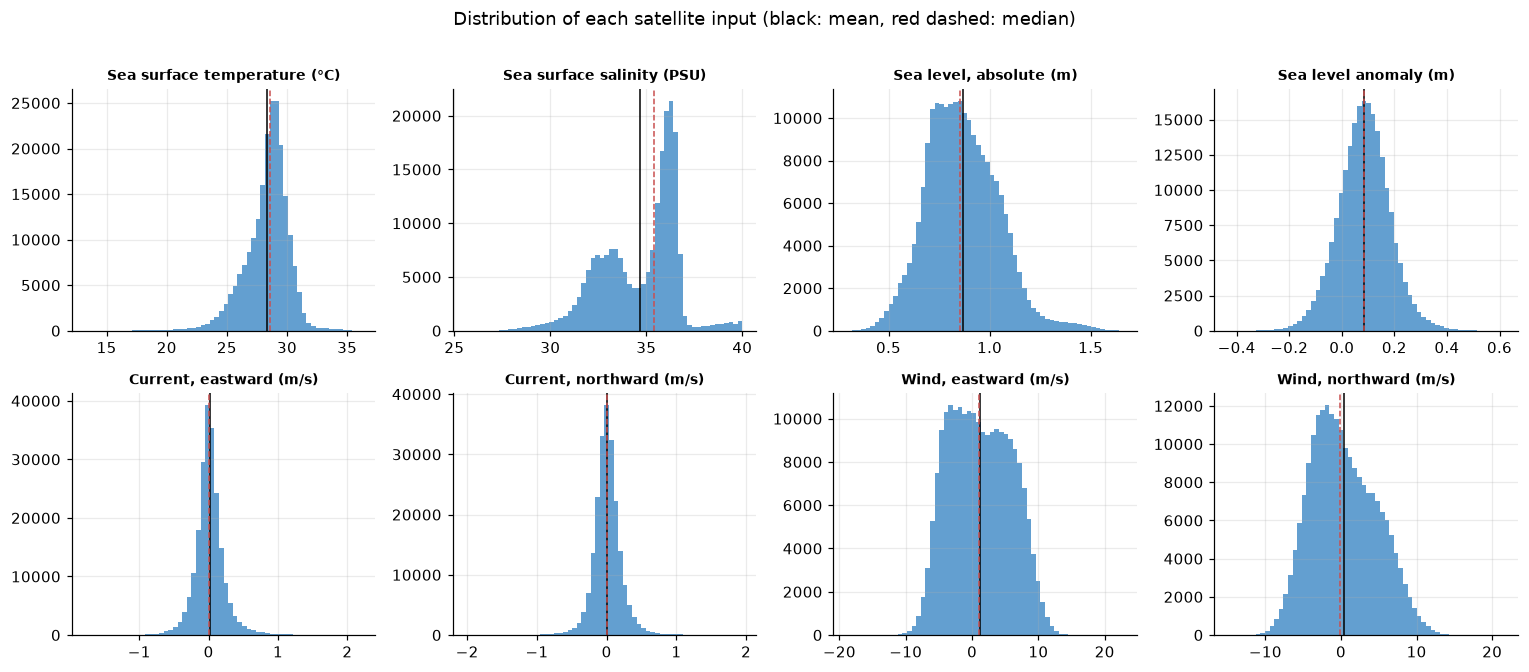

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, C.INPUTS):
    sns.histplot(df[col], bins=60, ax=ax, color=C.PALETTE["course"], edgecolor=None)
    ax.axvline(df[col].mean(), color="k", lw=1); ax.axvline(df[col].median(), color=C.PALETTE["accent"], lw=1, ls="--")
    ax.set_title(C.INPUT_NAMES[col], fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Distribution of each satellite input (black: mean, red dashed: median)", y=1.01)
fig.tight_layout(); C.save(fig, "explore_inputs_hist")

Salinity has a long tail to the left (25–33 PSU). That is the **Bay of Bengal**, which
receives fresh water from the Ganges, Brahmaputra and Irrawaddy. Mean and median
disagree when a distribution is skewed like this, and the median is the more honest
"typical value". Winds and currents are centred near zero because they blow and flow
both ways.

## 2.3 What the water column looks like, by sea and by season

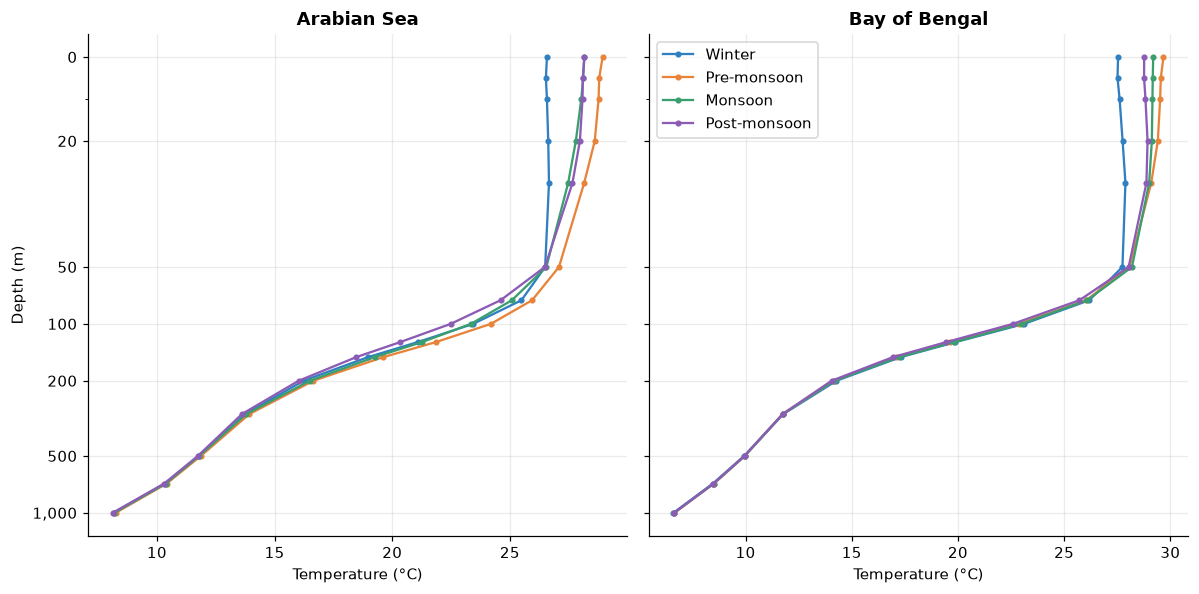

In [7]:
prof = df.groupby(["basin", "season"])[C.TARGETS].mean()
order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
cols = dict(zip(order, ["#2f7fc1", "#e8833a", "#3a9e6f", "#8c5bb5"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
for ax, basin in zip(axes, ["Arabian Sea", "Bay of Bengal"]):
    for s in order:
        ax.plot(prof.loc[(basin, s)].values, C.DEPTHS, label=s, color=cols[s], marker=".")
    ax.set_title(basin); ax.set_xlabel("Temperature (°C)"); ax.set_yscale("symlog", linthresh=50)
    ax.set_yticks([0, 20, 50, 100, 200, 500, 1000]); ax.set_yticklabels([0, 20, 50, 100, 200, 500, "1,000"])
axes[0].invert_yaxis(); axes[0].set_ylabel("Depth (m)"); axes[1].legend()
fig.tight_layout(); C.save(fig, "explore_profiles_season")

In [8]:
rank = (df.groupby(["basin", "season"])["t0"].mean().rename("surface °C").reset_index()
        .assign(rank=lambda d: d["surface °C"].rank(ascending=False).astype(int)).sort_values("rank"))
rank.round(2)

,basin,season,surface °C,rank
8,Other,Monsoon,29.97,1
6,Bay of Bengal,Pre-monsoon,29.68,2
4,Bay of Bengal,Monsoon,29.20,3
2,Arabian Sea,Pre-monsoon,28.94,4
5,Bay of Bengal,Post-monsoon,28.77,5
9,Other,Post-monsoon,28.32,6
10,Other,Pre-monsoon,28.26,7
1,Arabian Sea,Post-monsoon,28.16,8
0,Arabian Sea,Monsoon,28.16,9
7,Bay of Bengal,Winter,27.54,10


The two seas are different worlds. The Bay of Bengal is warmer at the surface but
colder below 150 m: its thermocline is sharper (it cools by about 11 °C between 50 and
150 m, against about 7 °C in the Arabian Sea). The pre-monsoon (March to May) is the hottest
season at the surface in both seas, which is when the strongest cyclones of the year
form. Below 300 m the seasons almost coincide: the deep ocean does not feel the
monsoon.

## 2.4 Correlation: which surface signal speaks for which depth?

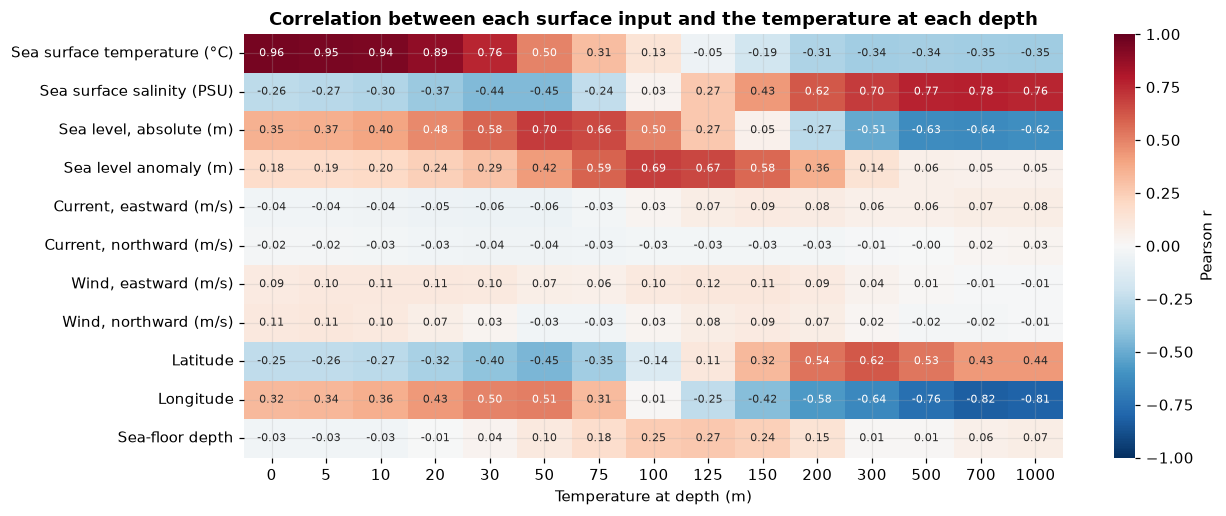

In [9]:
features = C.INPUTS + ["lat", "lon", "bathy"]
corr = df[features + C.TARGETS].corr().loc[features, C.TARGETS]
corr.columns = [f"{d}" for d in C.DEPTHS]
corr.index = [C.INPUT_NAMES.get(f, {"lat": "Latitude", "lon": "Longitude", "bathy": "Sea-floor depth"}.get(f)) for f in features]
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_xlabel("Temperature at depth (m)"); ax.set_title("Correlation between each surface input and the temperature at each depth")
C.save(fig, "explore_corr_heatmap")
C.record("explore.corr", {i: corr.loc[C.INPUT_NAMES[i]].round(3).to_dict() for i in ["sst", "sss", "adt", "sla"]})

Three patterns stand out:

* **Sea surface temperature** is almost perfectly correlated with the temperature at
  0–20 m, and the link fades to nothing by 100–125 m. The satellite sees the top layer
  and nothing below.
* **Sea level anomaly** (how much higher or lower the sea stands than its long-term
  average) is weakly related to the surface but strongly to **75–150 m**, the
  thermocline. Warm water takes up more space than cold water, so when the warm layer
  is thicker than usual the sea surface bulges up by a few centimetres. A satellite
  measuring sea height is indirectly measuring the heat underneath.
* **Salinity correlates with the deep water (500–1,000 m)**, but not because salt
  warms the deep ocean. The salty Arabian Sea also happens to have warmer deep water
  than the Bay of Bengal. The correlation comes from *geography*, a hidden third
  variable. **Correlation is not causation.**

This is why a model can predict below the surface at all, and why it needs sea level
and not just temperature.

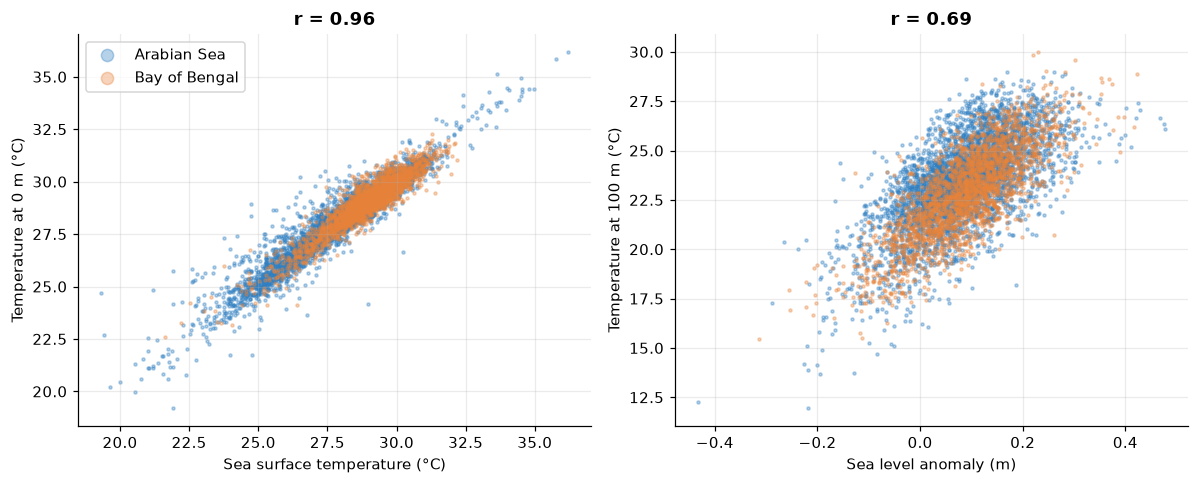

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
s = df.sample(8000, random_state=C.SEED)
for ax, (x, y) in zip(axes, [("sst", "t0"), ("sla", "t100")]):
    for basin, col in [("Arabian Sea", C.PALETTE["course"]), ("Bay of Bengal", C.PALETTE["deep"])]:
        p = s[s["basin"] == basin]
        ax.scatter(p[x], p[y], s=4, alpha=0.35, color=col, label=basin)
    r = df[[x, y]].corr().iloc[0, 1]
    ax.set_xlabel(C.INPUT_NAMES[x]); ax.set_ylabel(f"Temperature at {y[1:]} m (°C)")
    ax.set_title(f"r = {r:.2f}")
axes[0].legend(markerscale=4)
fig.tight_layout(); C.save(fig, "explore_scatter")

## 2.5 Estimation and a first hypothesis test

**Question:** is the surface of the Bay of Bengal fresher than the Arabian Sea's?

* H₀ (null): the mean surface salinity is the same in both seas.
* H₁ (alternative): the means differ (two-sided).

Patches sampled on the same day are not independent (neighbouring water is alike), so
a test on 200,000 rows would wildly overstate the evidence. We reduce each sea to one
mean per day, and compare the two seas **day by day** with a paired t-test.

In [11]:
daily = (df[df["basin"] != "Other"].groupby(["day", "basin"])["sss"].mean().unstack().dropna())
diff = daily["Arabian Sea"] - daily["Bay of Bengal"]
t, p = stats.ttest_rel(daily["Arabian Sea"], daily["Bay of Bengal"])
ci = stats.t.interval(0.95, len(diff) - 1, loc=diff.mean(), scale=stats.sem(diff))
mean_ci = {b: stats.t.interval(0.95, len(daily) - 1, loc=daily[b].mean(), scale=stats.sem(daily[b])) for b in daily}
print(f"Days compared: {len(daily):,}")
for b, (lo, hi) in mean_ci.items():
    print(f"  {b:14s} mean SSS {daily[b].mean():.2f} PSU, 95% CI [{lo:.2f}, {hi:.2f}]")
print(f"Difference (Arabian − Bay): {diff.mean():.2f} PSU, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")
print(f"t = {t:.1f}, p = {p:.1e}")
C.record("explore.salinity_test", {"days": len(daily), "mean_arabian": daily["Arabian Sea"].mean(),
                                   "mean_bay": daily["Bay of Bengal"].mean(), "diff": diff.mean(),
                                   "ci95": list(ci), "t": t, "p": p})

Days compared: 5,366
  Arabian Sea    mean SSS 35.95 PSU, 95% CI [35.94, 35.96]
  Bay of Bengal  mean SSS 32.58 PSU, 95% CI [32.57, 32.59]
Difference (Arabian − Bay): 3.37 PSU, 95% CI [3.35, 3.39]
t = 417.3, p = 0.0e+00


The Arabian Sea is saltier by more than 3 PSU, and the confidence interval is far from
zero. We **reject H₀**. The size of the difference matters as much as the p-value:
3 PSU is large in ocean terms. That fresh layer keeps the Bay's
surface warm and stable, which is part of why its cyclones intensify so fast.

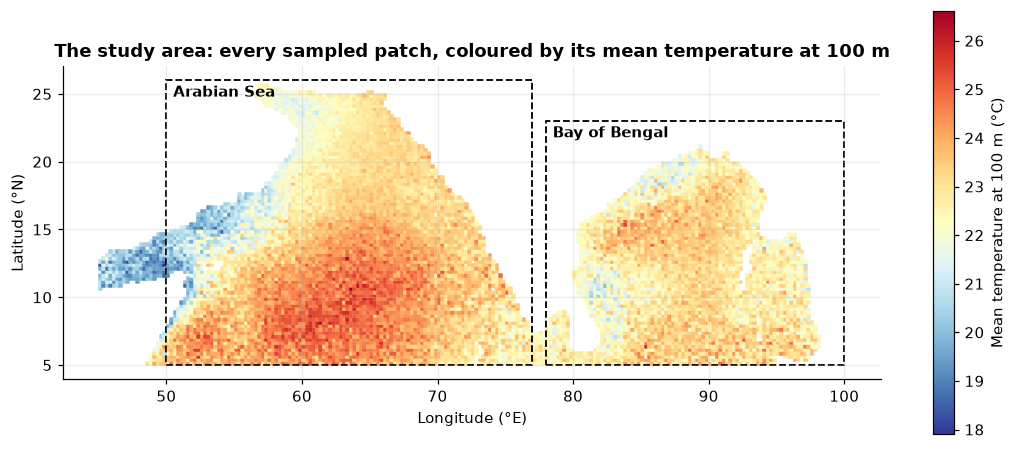

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
m = df.groupby(["lat", "lon"])["t100"].mean().reset_index()
sc = ax.scatter(m["lon"], m["lat"], c=m["t100"], s=3, cmap="RdYlBu_r", marker="s")
plt.colorbar(sc, ax=ax, label="Mean temperature at 100 m (°C)")
for name, b in C.BASINS.items():
    ax.add_patch(plt.Rectangle((b["lon"][0], b["lat"][0]), b["lon"][1] - b["lon"][0], b["lat"][1] - b["lat"][0],
                               fill=False, lw=1.2, ls="--", color="k"))
    ax.text(b["lon"][0] + 0.5, b["lat"][1] - 1.2, name, fontsize=10, weight="bold")
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)"); ax.set_aspect("equal")
ax.set_title("The study area: every sampled patch, coloured by its mean temperature at 100 m")
C.save(fig, "explore_map_t100")